In [29]:
import numpy as np
from scipy.stats import pareto
import matplotlib.pyplot as plt
bvalues=np.linspace(0,2,11)
for i in bvalues:
    mean, variance,skew=pareto.stats(i,moments='mvs')
    print(f"For b value={i:.3f}, mean is {mean:.5f}, variance is {variance:.5f} and skew is {skew:.5f}.")         
for i in range(3,30,3):
    mean, variance,skew=pareto.stats(i,moments='mvs')
    print(f"For b value={i:.3f}, mean is {mean:.5f}, variance is {variance:.5f} and skew is {skew:.5f}.")     


For b value=0.000, mean is nan, variance is nan and skew is nan.
For b value=0.200, mean is inf, variance is inf and skew is nan.
For b value=0.400, mean is inf, variance is inf and skew is nan.
For b value=0.600, mean is inf, variance is inf and skew is nan.
For b value=0.800, mean is inf, variance is inf and skew is nan.
For b value=1.000, mean is inf, variance is inf and skew is nan.
For b value=1.200, mean is 6.00000, variance is inf and skew is nan.
For b value=1.400, mean is 3.50000, variance is inf and skew is nan.
For b value=1.600, mean is 2.66667, variance is inf and skew is nan.
For b value=1.800, mean is 2.25000, variance is inf and skew is nan.
For b value=2.000, mean is 2.00000, variance is inf and skew is nan.
For b value=3.000, mean is 1.50000, variance is 0.75000 and skew is nan.
For b value=6.000, mean is 1.20000, variance is 0.06000 and skew is 3.81032.
For b value=9.000, mean is 1.12500, variance is 0.02009 and skew is 2.93972.
For b value=12.000, mean is 1.09091, v

## Observations for b value between 0 and 2

- Variance is infinite but nan at 0 and 2
- Mean is infinite till 1 and nan for 0
- Mean becomes a finite number after 1 and decreases after that
- Skew is nan till 2 (and also after that) but becomes a number at the entry 6.
- Data till b=27 is considered highly skewed (values above 1) 

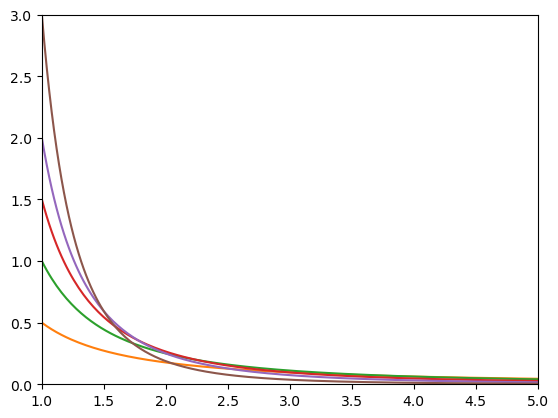

In [53]:
b=[0,0.5,1,1.5,2,3]
x=np.linspace(1,100,5000)
for a in b:
    plt.plot(x,pareto.pdf(x,a))
    plt.xlim(1, 5)
    plt.ylim(0, 3)

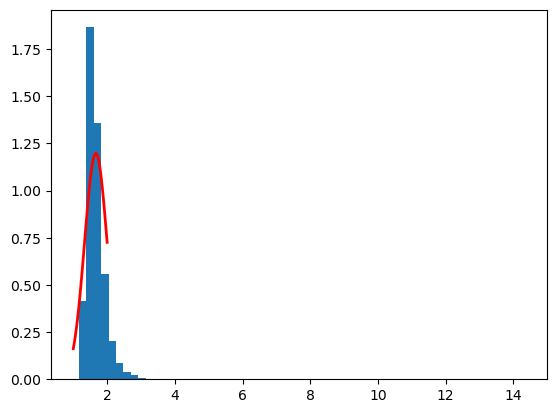

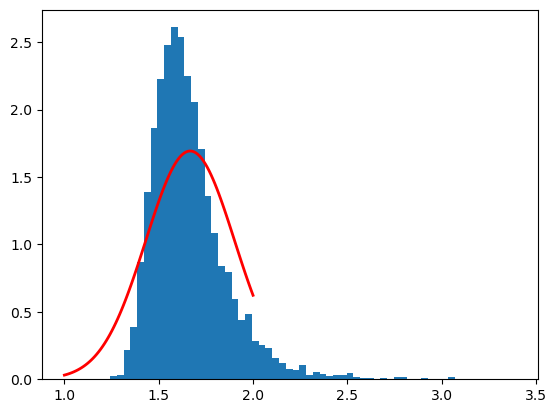

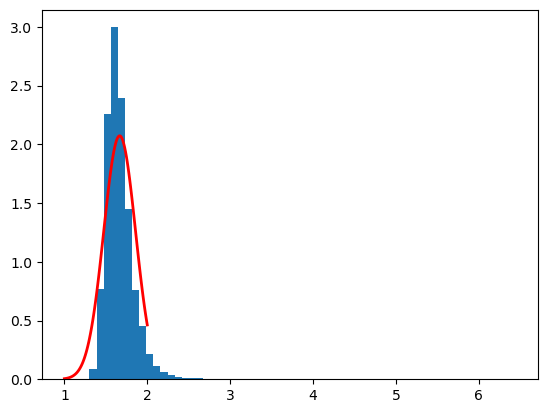

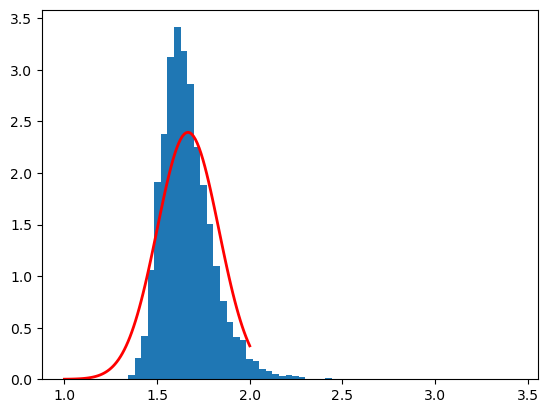

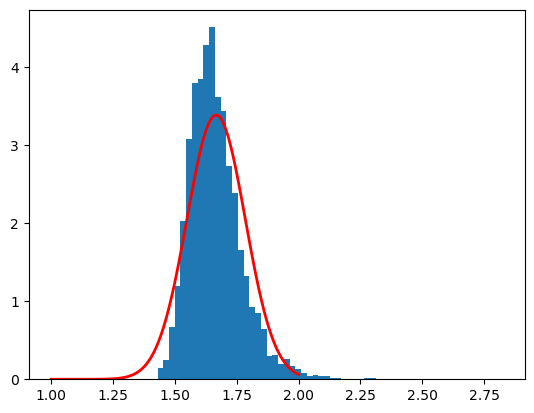

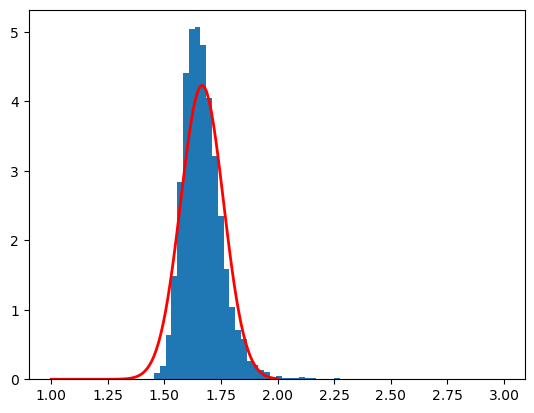

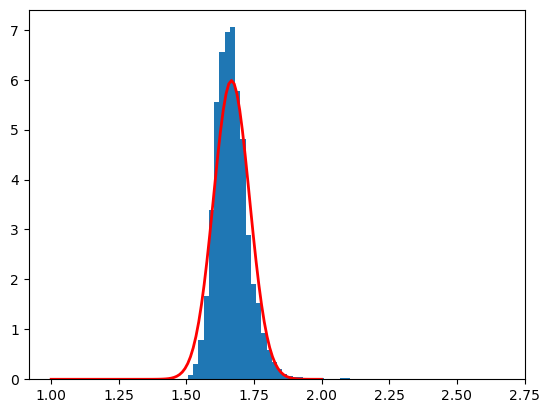

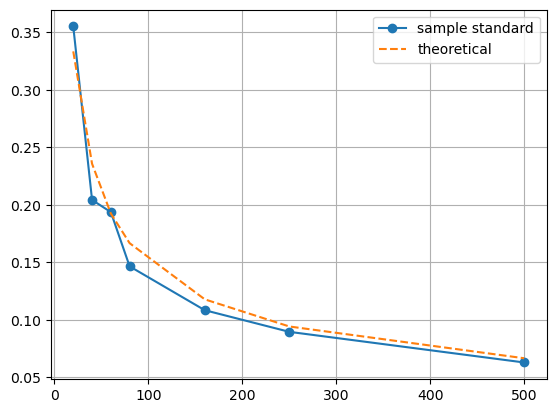

In [78]:
samplesizes=[20,40,60,80,160,250,500]
parameter_b=2.5
samp_deviation=[]
theory_deviation=[]
dev_theory=1.4907
dev_mean=1.6667

for n in samplesizes:
    means=[]
    for i in range (5000):
        X=np.random.pareto(parameter_b,n)+1
        means.append(np.mean(X))
            
    current_deviation=np.std(means)
    samp_deviation.append(current_deviation)
    theory_deviation.append(dev_theory/np.sqrt(n))

    
    plt.figure()
    plt.hist(means,bins=60,density=True)
    x = np.linspace(1.0, 2.0, 100)
    plt.plot(x, scipy_norm.pdf(x,dev_mean,dev_theory/np.sqrt(n)), color='red', linewidth=2)
plt.figure()
plt.plot(samplesizes,samp_deviation,'o-',label='sample standard')
plt.plot(samplesizes,theory_deviation, '--',label='theoretical')
plt.legend()
plt.grid(True)

### CLT holding for different values of the parameter b

The Central Limit Theorem **does not hold for all values** of the Pareto shape parameter $b$. For CLT to apply, the distribution must have a **finite variance**. Therefore the behavior of sample means depends directly on $b$: Since CLT requires finite variance and pareto variance only exists when $b \le 2$, the theorem fails.

* **$b > 2$ (CLT holds):** Both mean and variance are finite. As sample size $n$ increases, the distribution of sample means converges smoothly into a symmetric **normal curve**. The standard deviation shrinks proportional to $1/\sqrt{n}$.
* **$1 < b \le 2$ (CLT fails):** The mean is finite, but the variance is **infinite ($\infty$)**. Due to frequent extreme outliers, sample means do not form a bell curve...
* **$b \le 1$ (CLT fails):** Both mean and variance are **infinite ($\infty$)**. Sample averages fluctuate and never settle on a single value, regardless of sample size.
